In [1]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

import pandas as pd

# ============================================================
# 0. 데이터 불러오기: 2-5 train_test_comparison에서 제거된 이상치까지 반영된 데이터셋
# ============================================================

train = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '3_train_clean3.parquet')
val = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '3_val_clean3.parquet')

print(train.shape, val.shape)

from sklearn import set_config
set_config(display='text')
# scikit-learn의 HTML 출력 과정에서 발생한 cp949 간 UTF-8 충돌 때문에 넣는 코드

(616293, 35) (133316, 35)


In [2]:
# ============================================================
# 0. 라이브러리 불러오기
# ============================================================

import numpy as np

from catboost import CatBoostRegressor
from sklearn.metrics import root_mean_squared_error

In [3]:
# ============================================================
# 1. 컬럼군 정의
# ============================================================

target_col = 'target_maxrise_6h'  # 모델링 학습부터는 반드시 빼내야 함

# 수위 컬럼군
wl_cols = [
    'wl_t',
    'wl_t_minus_1h',
    'wl_t_minus_3h',
    'wl_t_minus_6h',
    'wl_t_minus_12h',
    'wl_t_minus_24h',
]

# 수위차분(wl_diff) 컬럼군
wl_diff_cols = [
    'wl_t',
    'wl_diff_1h',
    'wl_diff_3h',
    'wl_diff_6h',
    'wl_diff_12h',
    'wl_diff_24h'
]


# 강수 컬럼군
rain_cols = [
    # IMERG강우
    'imerg_rain_1h',
    'imerg_rain_6h',
    'imerg_rain_24h',
    # 지상강우
    'sfc_rain_1h',
    'sfc_rain_6h',
    'sfc_rain_24h',
    # 레이더 반사도
    'radar_reflectivity_mean',
    'radar_reflectivity_p95',
    'radar_reflectivity_ge20_fraction'
]

# 강우강도 컬럼군
rain_int_cols = [
    'imerg_rain_1h',
    'imerg_int_1to6h',
    'imerg_int_6to24h',
    'sfc_rain_1h',
    'sfc_int_1to6h',
    'sfc_int_6to24h'
]

# 환경 컬럼군
env_cols = [
    'cat_area',       # km²
    'wsarea',         # km²
    'mean_elevation', # m
    'mean_slope',     # °
    'urban_ratio',    # %
    'forest_ratio',   # %
    'stream_order'
]

num_cols = wl_cols + rain_cols + env_cols
num_cols_fe_wl = num_cols + [
    col for col in wl_diff_cols if col != 'wl_t'
]
num_cols_fe = num_cols_fe_wl + [
    col for col in rain_int_cols if col not in ['imerg_rain_1h', 'sfc_rain_1h']
]

print(f"""<변수개수 검증>
    수위변수: {len(wl_cols)}
    강우변수: {len(rain_cols)}, 
    환경변수: {len(env_cols)}, 
    수위차분(wl_t포함): {len(wl_diff_cols)},
    강우강도(rain_1h포함): {len(rain_int_cols)}
    기존 숫자열(수위 + 강우 + 환경): {len(num_cols)}, 
    수위차분추가 숫자열(수위 + 강우 + 환경 + 수위차분(wl_t제외)): {len(num_cols_fe_wl)},
    강우강도추가 숫자열(수위차분추가 숫자열 + 강우강도(rain_1h 2개제외)): {len(num_cols_fe)}
""")

<변수개수 검증>
    수위변수: 6
    강우변수: 9, 
    환경변수: 7, 
    수위차분(wl_t포함): 6,
    강우강도(rain_1h포함): 6
    기존 숫자열(수위 + 강우 + 환경): 22, 
    수위차분추가 숫자열(수위 + 강우 + 환경 + 수위차분(wl_t제외)): 27,
    강우강도추가 숫자열(수위차분추가 숫자열 + 강우강도(rain_1h 2개제외)): 31



In [4]:
# ============================================================
# 2. 종속변수 설정
# ============================================================

y_train = train[target_col]
y_val = val[target_col]

In [ ]:
# ============================================================
# 3. 시간사상 Group K-Fold 설정: 분할 전 적적성 검증
# ============================================================


# ------------------------------------------------------------
# 3-1. Group 설정
# 같은 시간사상에 속한 관측치는 반드시 같은 fold에 들어가도록 설정
# ------------------------------------------------------------

# 실제 시간사상 ID 컬럼명
kf_groups = train['event_id']

print(f'<시간사상 Group 확인>')
print(f'전체 학습 행 수   : {len(train):,}')
print(f'시간사상 개수     : {kf_groups.nunique():,}')
print()


# ------------------------------------------------------------
# 3-2. 기존 OOF에서 추출한 사상별 fold 배정 불러오기
# ------------------------------------------------------------

N_SPLITS = 5  # 기존 5-Fold 유지

kf_fold_map = pd.read_csv(
    PROJECT_ROOT / 'config' / '0_kf_event_fold_match.csv'
)
# 새로운 사상/누락/중복이 있으면 재분할하지 않고 중단한다.
assert kf_fold_map.columns.tolist() == ['event_id', 'fold_num']
assert not kf_fold_map.isna().any().any()
assert kf_fold_map['event_id'].is_unique
assert set(kf_fold_map['fold_num']) == set(range(1, N_SPLITS + 1))
assert not kf_groups.isna().any()
assert set(kf_groups) == set(kf_fold_map['event_id'])

kf_fold_num = kf_groups.map(kf_fold_map.set_index('event_id')['fold_num'])
assert kf_fold_num.notna().all()

# 행 위치 배열만 보관한다. 데이터셋은 복사하지 않는다.
# 학습·진단·OOF fold 기록에서 모두 같은 분할을 재사용한다.
kf_splits = [
    (
        np.flatnonzero(kf_fold_num.to_numpy() != fold),
        np.flatnonzero(kf_fold_num.to_numpy() == fold)
    )
    for fold in range(1, N_SPLITS + 1)
]

# ------------------------------------------------------------
# 3-3. Fold 검증
# ------------------------------------------------------------

for fold, (train_idx, valid_idx) in enumerate(
    kf_splits,
    start=1
):
    # 고정한 분할의 사상 중복 여부 검증
    train_groups = set(kf_groups.iloc[train_idx])  # 분할된 event_id
    valid_groups = set(kf_groups.iloc[valid_idx])  # 분할된 event_id

    overlap = train_groups & valid_groups  # 교집합은 0이어야함

    print(
        f'Fold {fold} | '
        f'train={len(train_idx):,} | '
        f'valid={len(valid_idx):,} | '
        f'train events={len(train_groups):,} | '
        f'valid events={len(valid_groups):,} | '
        f'event overlap={len(overlap)}'
    )

<시간사상 Group 확인>
전체 학습 행 수   : 616,293
시간사상 개수     : 98

Fold 1 | train=493,297 | valid=122,996 | train events=82 | valid events=16 | event overlap=0
Fold 2 | train=492,894 | valid=123,399 | train events=77 | valid events=21 | event overlap=0
Fold 3 | train=492,894 | valid=123,399 | train events=77 | valid events=21 | event overlap=0
Fold 4 | train=493,077 | valid=123,216 | train events=78 | valid events=20 | event overlap=0
Fold 5 | train=493,010 | valid=123,283 | train events=78 | valid events=20 | event overlap=0


In [6]:
# ============================================================
# 4. no_ohe 모델용 station_id가 포함된 X_train 데이터셋 만들기
# ============================================================

X_train_with_station = train[num_cols_fe + ['station_id']].copy()

# no_ohe 모델은 str int 자료형만 받음
print(X_train_with_station['station_id'].dtype)
print(X_train_with_station['station_id'].isna().sum())
print(train['station_id'].map(type).value_counts())

str
0
station_id
<class 'str'>    616293
Name: count, dtype: int64


In [7]:
# ============================================================
# 5. GroupKFold 기반 학습·검증 데이터 분할, 모델링
# ============================================================
# 메모리 사용을 줄이고, 효율적 코딩을 위해서는 폴드별로 데이터셋을 저장 X
# 데이터 분할 + 모델링을 한 세트로 for문을 구현

kf_results = []
kf_oof_pred = np.full(len(X_train_with_station), np.nan)

for fold_num, (train_idx, val_idx) in enumerate(
    kf_splits,
    start=1
):
    # fold별 데이터 분할
    X_kf_tr = X_train_with_station.iloc[train_idx]
    X_kf_va = X_train_with_station.iloc[val_idx]

    y_kf_tr = y_train.iloc[train_idx]
    y_kf_va = y_train.iloc[val_idx]

    # 모델 정의
    model_cat_kf = CatBoostRegressor(
        random_state=42,
        iterations=3000,
        cat_features=['station_id']  # CatBoost 전용 범주형변수 매개변수
    )

    # 학습
    model_cat_kf.fit(
        X_kf_tr,
        y_kf_tr,
        early_stopping_rounds=100,
        eval_set=(X_kf_va, y_kf_va),
        verbose=200
    )

    # 예측
    pred_kf_va = model_cat_kf.predict(X_kf_va)
    pred_kf_tr = model_cat_kf.predict(X_kf_tr)
    kf_oof_pred[val_idx] = pred_kf_va

    # 평가
    val_rmse = root_mean_squared_error(y_kf_va, pred_kf_va)
    train_rmse = root_mean_squared_error(y_kf_tr, pred_kf_tr)

    # 평가 결과 저장
    kf_results.append({
        'fold': fold_num,
        'val_rmse': val_rmse,
        'train_rmse': train_rmse,
        'gap': val_rmse - train_rmse,
        'best_iteration': model_cat_kf.best_iteration_
    })

    # 결과 출력
    print(
        f'Fold {fold_num} | '
        f'Val={val_rmse:.4f} | '
        f'Train={train_rmse:.4f} | '
        f'Gap={val_rmse - train_rmse:.4f} | '
        f'Best iter={model_cat_kf.best_iteration_}'
    )

# oof_RMSE 구하기
# 예측값 누락 확인
print(pd.isnull(kf_oof_pred).sum())

# 전체 OOF RMSE
oof_rmse = root_mean_squared_error(y_train, kf_oof_pred)

print(f'OOF RMSE: {oof_rmse:.4f}')

Learning rate set to 0.068972
0:	learn: 0.3781888	test: 0.4351678	best: 0.4351678 (0)	total: 403ms	remaining: 20m 9s
200:	learn: 0.2186215	test: 0.2806116	best: 0.2806116 (200)	total: 33.3s	remaining: 7m 43s
400:	learn: 0.2058961	test: 0.2742323	best: 0.2742323 (400)	total: 1m 4s	remaining: 6m 55s
600:	learn: 0.1982738	test: 0.2727407	best: 0.2726256 (578)	total: 1m 38s	remaining: 6m 31s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.2726256368
bestIteration = 578

Shrink model to first 579 iterations.
Fold 1 | Val=0.2726 | Train=0.1978 | Gap=0.0748 | Best iter=578
Learning rate set to 0.068963
0:	learn: 0.4063712	test: 0.3168128	best: 0.3168128 (0)	total: 180ms	remaining: 8m 58s
200:	learn: 0.2455789	test: 0.1575049	best: 0.1575049 (200)	total: 28.7s	remaining: 6m 39s
400:	learn: 0.2321372	test: 0.1513555	best: 0.1513555 (400)	total: 58s	remaining: 6m 16s
600:	learn: 0.2240423	test: 0.1493390	best: 0.1493390 (600)	total: 1m 28s	remaining: 5m 54s
800:	learn: 0.218

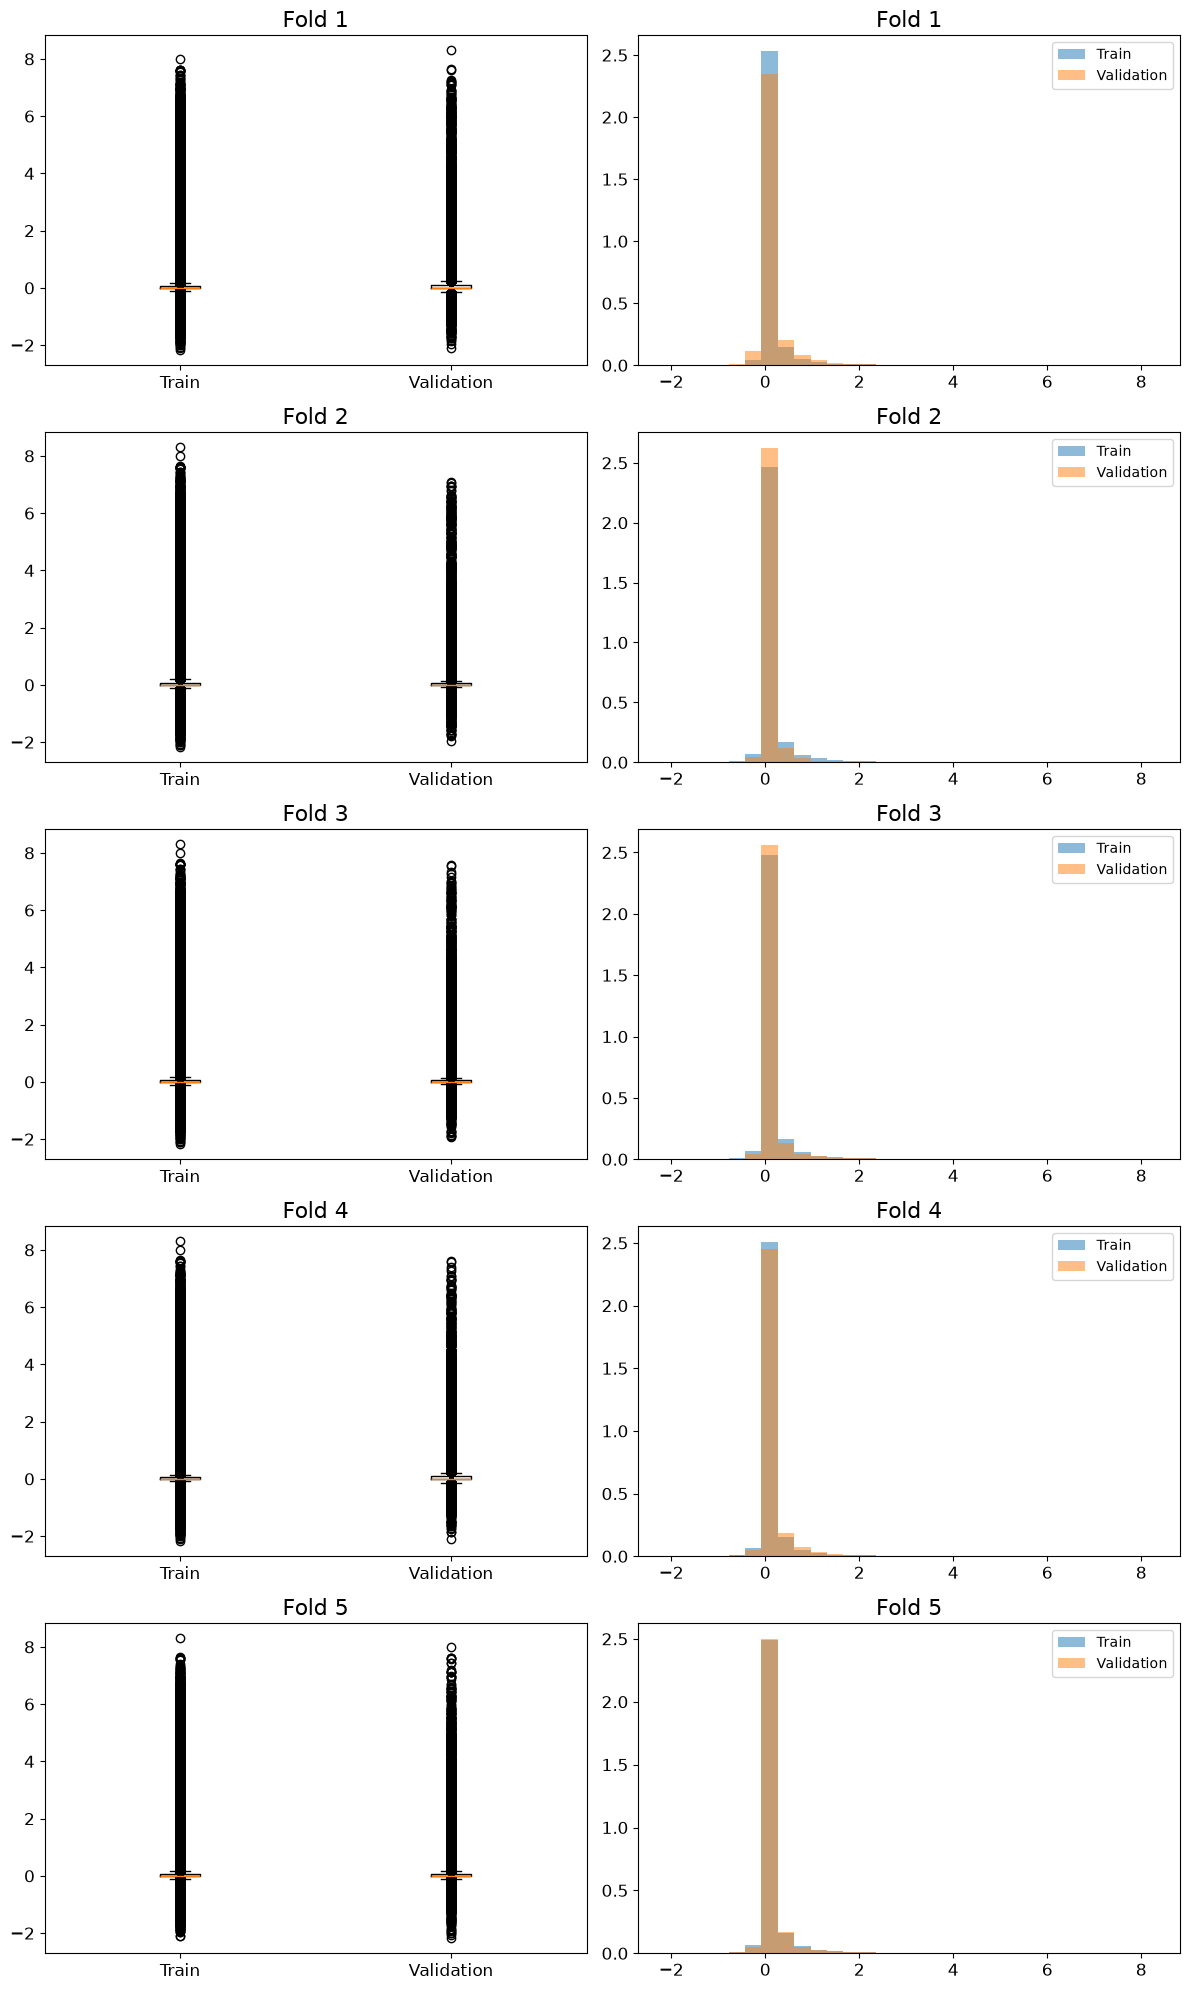

In [8]:
# ======================================================================
# 6-1. Fold별 Train, Validation 종속변수 분포 비교 (박스플롯, 히스토그램)
# ======================================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    N_SPLITS,  # 그래프 행 개수: K만큼
    2, 
    figsize=(12, 4 * N_SPLITS))

for i, (train_idx, val_idx) in enumerate(
    kf_splits
):
    tr = y_train.iloc[train_idx].dropna()
    va = y_train.iloc[val_idx].dropna()

    axes[i][0].boxplot([tr, va], tick_labels=['Train', 'Validation'])
    axes[i][0].set_title(f'Fold {i+1}', fontsize=16)
    axes[i][0].tick_params(labelsize=12)

    axes[i][1].hist(
        tr,
        range=(min(tr.min(), va.min()), max(tr.max(), va.max())),
        bins=30,
        alpha=0.5,
        density=True,
        label='Train'
    )
    axes[i][1].hist(
        va,
        range=(min(tr.min(), va.min()), max(tr.max(), va.max())),
        bins=30,
        alpha=0.5,
        density=True,
        label='Validation'
    )
    axes[i][1].set_title(f'Fold {i+1}', fontsize=16)
    axes[i][1].tick_params(labelsize=12)
    axes[i][1].legend()

plt.tight_layout()
plt.show()

In [9]:
# ======================================================================
# 6-2. Fold별 Train, Validation 종속변수 기초통계량 비교
# ======================================================================

q = [0, 0.01, 0.05, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0]

for fold, (train_idx, val_idx) in enumerate(
    kf_splits,
    start=1
):
    tr = y_train.iloc[train_idx]
    va = y_train.iloc[val_idx]

    print(f'Fold {fold}')
    print(
        pd.DataFrame({
            'Train': tr.quantile(q).round(3),
            'Validation': va.quantile(q).round(3),
            'Val/Train': (va.quantile(q) / tr.quantile(q)).round(3)
        }).to_csv(sep='\t')
    )
    print()

Fold 1
	Train	Validation	Val/Train
0.0	-2.18	-2.09	0.959
0.01	-0.18	-0.26	1.444
0.05	-0.02	-0.08	4.0
0.5	0.01	0.01	1.0
0.75	0.07	0.09	1.286
0.9	0.25	0.4	1.6
0.95	0.53	0.77	1.453
0.99	1.89	2.11	1.116
1.0	7.98	8.3	1.04


Fold 2
	Train	Validation	Val/Train
0.0	-2.18	-1.96	0.899
0.01	-0.21	-0.16	0.762
0.05	-0.04	-0.02	0.5
0.5	0.01	0.01	1.0
0.75	0.08	0.05	0.625
0.9	0.31	0.17	0.548
0.95	0.65	0.35	0.538
0.99	2.06	1.25	0.607
1.0	8.3	7.1	0.855


Fold 3
	Train	Validation	Val/Train
0.0	-2.18	-1.93	0.885
0.01	-0.21	-0.16	0.762
0.05	-0.04	-0.02	0.5
0.5	0.01	0.01	1.0
0.75	0.07	0.06	0.857
0.9	0.29	0.22	0.759
0.95	0.6	0.51	0.85
0.99	1.92	2.03	1.057
1.0	8.3	7.57	0.912


Fold 4
	Train	Validation	Val/Train
0.0	-2.18	-2.1	0.963
0.01	-0.2	-0.19	0.95
0.05	-0.04	-0.03	0.75
0.5	0.01	0.01	1.0
0.75	0.06	0.09	1.5
0.9	0.26	0.34	1.308
0.95	0.56	0.69	1.232
0.99	1.92	2.0	1.042
1.0	8.3	7.6	0.916


Fold 5
	Train	Validation	Val/Train
0.0	-2.1	-2.18	1.038
0.01	-0.2	-0.19	0.95
0.05	-0.04	-0.03	0.75
0.5	0.01	0.01	1.0
0.75

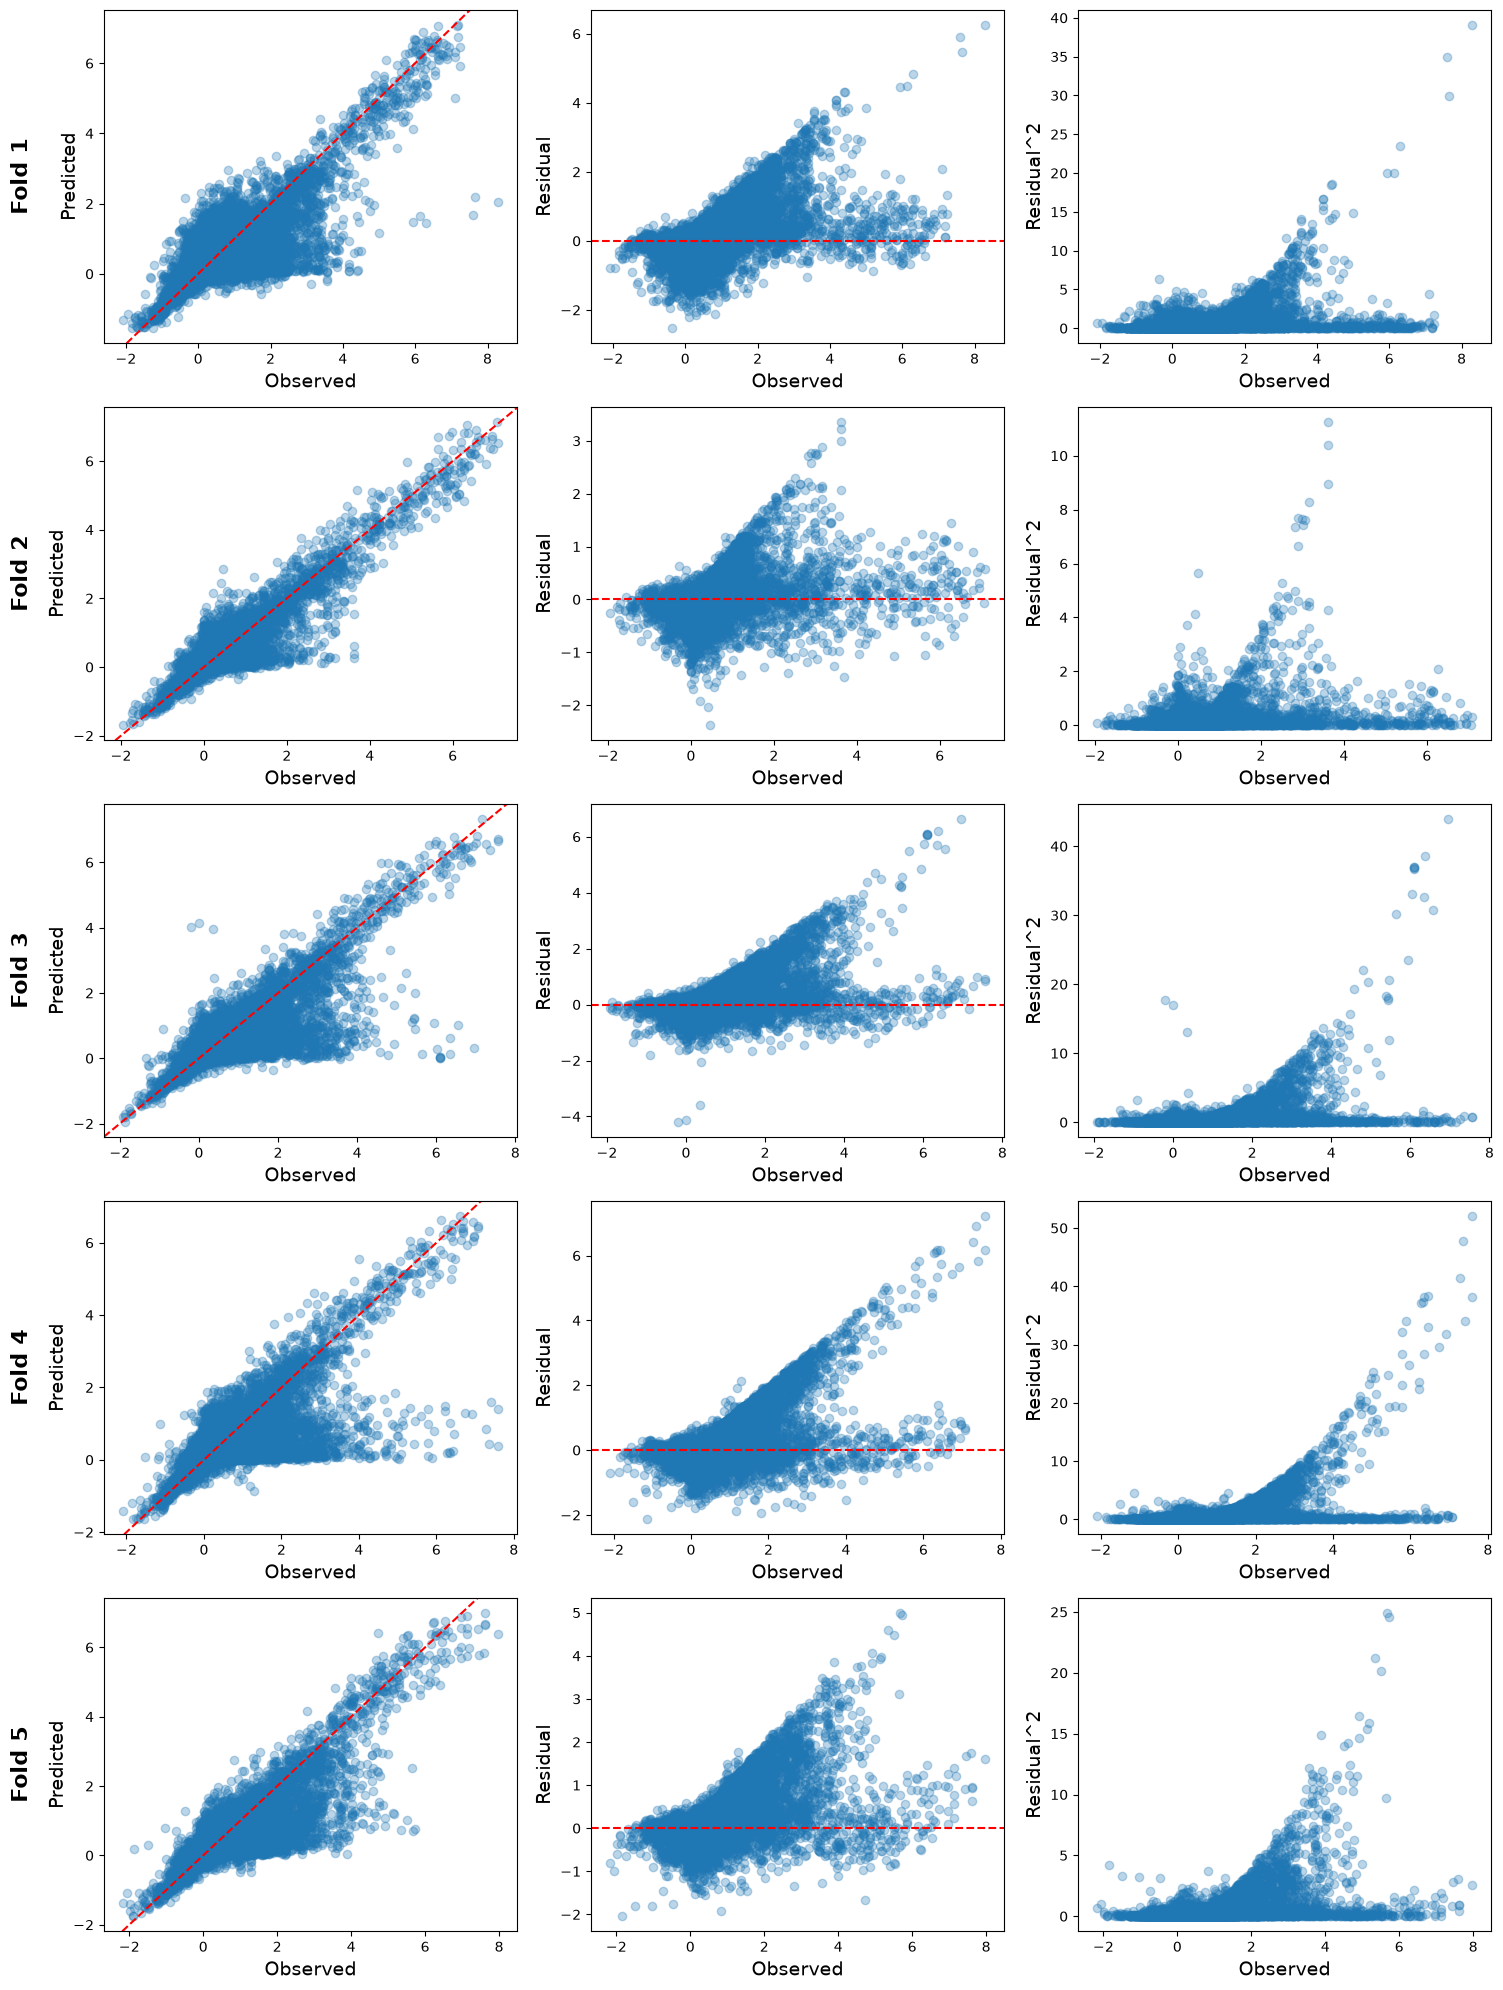

In [10]:
# ======================================================================
# 6-3. Fold별 OOF 예측값 분석: 산점도, 잔차, 잔차제곱
# ======================================================================

fig, axes = plt.subplots(
    N_SPLITS, 3,
    figsize=(15, 4 * N_SPLITS)
)

for i, (train_idx, val_idx) in enumerate(
    kf_splits
):
    y_va = y_train.iloc[val_idx]
    pred_va = kf_oof_pred[val_idx]

    # 잔차 계산
    resid_va = y_va - pred_va

    # Fold 번호 표시
    axes[i][0].text(
        -0.2, 0.5,
        f'Fold {i+1}',
        transform=axes[i][0].transAxes,
        rotation=90,
        fontsize=16,
        fontweight='bold',
        ha='center',
        va='center'
    )

    # 1열: 실제값 vs 예측값
    axes[i][0].scatter(
        y_va, pred_va,
        alpha=0.3,
        label='Validation'
    )
    axes[i][0].set_xlabel('Observed', fontsize=14)
    axes[i][0].set_ylabel('Predicted', fontsize=14)
    axes[i][0].axline((0, 0), slope=1, color='red', linestyle='--')

    # 2열: 실제값 vs 잔차
    axes[i][1].scatter(
        y_va, resid_va,
        alpha=0.3
    )
    axes[i][1].set_xlabel('Observed', fontsize=14)
    axes[i][1].set_ylabel('Residual', fontsize=14)
    axes[i][1].axhline(y=0, color='red', linestyle='--')

    # 3열: 실제값 vs 잔차제곱
    axes[i][2].scatter(
        y_va, resid_va ** 2,
        alpha=0.3
    )
    axes[i][2].set_xlabel('Observed', fontsize=14)
    axes[i][2].set_ylabel('Residual^2', fontsize=14)

plt.tight_layout()
plt.show()

In [11]:
# ======================================================================
# 7. train셋에 관측값(실제값), 예측값, 잔차 붙이기
# ======================================================================

# 원래 Train의 row_id 인덱스를 그대로 유지한다.
assert train.index.name == 'row_id'
assert train.index.is_unique and not train.index.hasnans
assert 'row_id' not in train.columns

kf_train = train.copy()

kf_train['y_kf_val'] = y_train.to_numpy()
kf_train['y_kf_pred'] = kf_oof_pred
kf_train['resid'] = kf_train['y_kf_val'] - kf_train['y_kf_pred']
kf_train['resid_sq'] = kf_train['resid'] ** 2
kf_train['fold_num'] = 0

fold_col_idx = kf_train.columns.get_loc('fold_num')  # 'fold_num'열의 인덱스 번호를 반환함

for fold, (train_idx, val_idx) in enumerate(
    kf_splits,
    start=1
):
    kf_train.iloc[val_idx, fold_col_idx] = fold

print(kf_train.shape)

(616293, 40)


In [12]:
# ======================================================================
# 7-2. parquet 저장
# ======================================================================

kf_train.to_parquet(
    PROJECT_ROOT / 'parqueted_data' / '0_kf_oof_train2_index_fixed.parquet',
    index=True  # 원래 row_id 인덱스의 이름과 값을 함께 보존
)